In [1]:
import os, pickle, warnings, re, time
import numpy as np, pandas as pd
from scipy import stats
from sklearn.linear_model import Lasso
warnings.filterwarnings("ignore")

from miner import miner as mnr
from miner import subtypes, causal_inference as causalinf

BASE = os.path.expanduser("~/gbm_miner_ecoli/ecoli_miner")
os.makedirs(BASE, exist_ok=True)
PRECISE1K = os.path.expanduser("~/gbm_miner_ecoli/precise1k/data")

EXPR_PATH = os.path.join(PRECISE1K, "precise1k", "log_tpm_qc.csv")
META_PATH = os.path.join(PRECISE1K, "precise1k", "metadata_qc.csv")
GENE_INFO_PATH = os.path.join(PRECISE1K, "annotation", "gene_info.csv")
TRN_PATH = os.path.join(PRECISE1K, "regulation", "TRN.csv")

In [2]:
def build_tf_database():
    gi = pd.read_csv(GENE_INFO_PATH)
    trn = pd.read_csv(TRN_PATH)
    expr = pd.read_csv(EXPR_PATH, index_col=0)
    expr_genes = set(expr.index)

    name_to_id = {}
    for _, row in gi.iterrows():
        if isinstance(row["gene_name"], str):
            name_to_id[row["gene_name"].lower()] = row["locus_tag"]
        if isinstance(row["synonyms"], str):
            for syn in row["synonyms"].split(";"):
                syn = syn.strip()
                if syn:
                    name_to_id[syn.lower()] = row["locus_tag"]
    for _, row in trn.dropna(subset=["gene_name", "gene_id"]).iterrows():
        name_to_id.setdefault(row["gene_name"].lower(), row["gene_id"])
    name_to_id.setdefault("h-ns", name_to_id.get("hns"))

    regulators = sorted(set(r for r in trn["regulator"].unique() if isinstance(r, str)))
    reg_to_id = {reg: name_to_id.get(reg.lower()) for reg in regulators}
    reg_to_id = {k: v for k, v in reg_to_id.items() if v and v in expr_genes}

    tf_to_genes = {}
    for reg, gid in reg_to_id.items():
        targets = trn[trn["regulator"] == reg]["gene_id"].dropna().unique()
        targets = [t for t in targets if t in expr_genes and t != gid]
        if len(targets) >= 5:
            tf_to_genes[gid] = sorted(set(targets))

    with open(os.path.join(BASE, "ecoli_tf_to_genes.pkl"), "wb") as f:
        pickle.dump(tf_to_genes, f)
    print(f"TF database: {len(tf_to_genes)} regulators")
    return tf_to_genes

tf_to_genes = build_tf_database()

TF database: 169 regulators


In [3]:
def build_perturbation_matrix():
    meta = pd.read_csv(META_PATH).set_index("Unnamed: 0")
    gi = pd.read_csv(GENE_INFO_PATH)
    expr = pd.read_csv(EXPR_PATH, index_col=0)
    samples = expr.columns.tolist()
    meta = meta.reindex(samples)

    name_to_id = {}
    for _, row in gi.iterrows():
        if isinstance(row["gene_name"], str):
            name_to_id[row["gene_name"].lower()] = row["locus_tag"]
        if isinstance(row["synonyms"], str):
            for syn in row["synonyms"].split(";"):
                syn = syn.strip()
                if syn:
                    name_to_id[syn.lower()] = row["locus_tag"]

    sample_ko, ko_gene_ids = {}, set()
    for s in samples:
        desc = str(meta.loc[s, "Strain Description"])
        full_ko = re.findall(r"del_(\w+)", desc)                    # e.g. del_crp
        domain_del = re.findall(r"(\w+?)_del[A-Za-z0-9]+", desc)    # e.g. crp_delAr1
        genes_hit = set(g.lower() for g in full_ko) | set(g.lower() for g in domain_del)
        ids = [name_to_id[g] for g in genes_hit if g in name_to_id]
        if ids:
            sample_ko[s] = ids
            ko_gene_ids.update(ids)

    mut_matrix = pd.DataFrame(0, index=samples, columns=sorted(ko_gene_ids))
    for s, ids in sample_ko.items():
        for gid in ids:
            mut_matrix.loc[s, gid] = 1
    mut_matrix.to_csv(os.path.join(BASE, "perturbation_matrix.csv"))
    n_crp = mut_matrix["b3357"].sum() if "b3357" in mut_matrix.columns else "N/A"
    print(f"Perturbation matrix: {mut_matrix.shape[1]} perturbed genes x {mut_matrix.shape[0]} samples "
          f"(CRP now has {n_crp} perturbed samples: 9 KO + 8 domain-deletion)")
    return mut_matrix

mut_matrix_samples_x_genes = build_perturbation_matrix()

Perturbation matrix: 70 perturbed genes x 1035 samples (CRP now has 17 perturbed samples: 9 KO + 8 domain-deletion)


In [4]:
%%time
expressionData = mnr.preprocess(EXPR_PATH, mapfile_path=None, do_preprocess_tpm=True)

initialClusters = mnr.cluster(expressionData, minNumberGenes=6,
                               minNumberOverExpSamples=4, maxSamplesExcluded=0.50)
revisedClusters = mnr.reviseInitialClusters(initialClusters, expressionData)
print(f"{len(revisedClusters)} revised co-expression clusters")

completed z-transformation.
Progress: |██████████████████████████████████████████████████| 100.0% Complete

coexpression clustering completed in 0.21 minutes
198 revised co-expression clusters
CPU times: user 29.4 s, sys: 1.42 s, total: 30.9 s
Wall time: 31.5 s


In [5]:
%%time
axes = mnr.principal_df(revisedClusters, expressionData, subkey=None, minNumberGenes=1)
mechanisticOutput = mnr.mechanisticInference(
    axes, revisedClusters, expressionData,
    correlationThreshold=0.2, numCores=4, p=0.05,
    database_path=os.path.join(BASE, "ecoli_tf_to_genes.pkl"))

coregulationModules = mnr.getCoregulationModules(mechanisticOutput)
regulons = mnr.getRegulons(coregulationModules, minNumberGenes=5, freqThreshold=0.333)
regulonModules, regulonDf = mnr.regulonDictionary(regulons)
regulonDf.to_csv(os.path.join(BASE, "regulonDf.csv"))

eigengenes = mnr.getEigengenes(regulonModules, expressionData, regulon_dict=None, saveFolder=None)
eigengenes.index = np.array(eigengenes.index).astype(str)
eigengenes = eigengenes * (np.percentile(expressionData, 95) / np.percentile(eigengenes, 95))  # eigenScale fix

print(f"{len(regulonModules)} regulons, {regulonDf['Regulator'].nunique()} regulators, "
      f"{regulonDf['Gene'].nunique()} co-regulated genes")

81 regulons, 47 regulators, 539 co-regulated genes
CPU times: user 2 s, sys: 160 ms, total: 2.16 s
Wall time: 8.71 s


In [6]:
%%time
bkgd = mnr.background_df(expressionData)
overExpressedMembers = mnr.biclusterMembershipDictionary(regulonModules, bkgd, label=2, p=0.05)
underExpressedMembers = mnr.biclusterMembershipDictionary(regulonModules, bkgd, label=0, p=0.05)
overExpressedMembersMatrix = mnr.membershipToIncidence(overExpressedMembers, expressionData)
underExpressedMembersMatrix = mnr.membershipToIncidence(underExpressedMembers, expressionData)
overExpressedMembersMatrix.columns = overExpressedMembersMatrix.columns.astype(str)
underExpressedMembersMatrix.columns = underExpressedMembersMatrix.columns.astype(str)
overExpressedMembersMatrix.to_csv(os.path.join(BASE, "overExpressedMembers.csv"))
underExpressedMembersMatrix.to_csv(os.path.join(BASE, "underExpressedMembers.csv"))

CPU times: user 2.72 s, sys: 63.2 ms, total: 2.79 s
Wall time: 2.94 s


In [7]:
%%time
minClusterSize = int(np.ceil(0.01 * expressionData.shape[1]))
referenceMatrix = overExpressedMembersMatrix - underExpressedMembersMatrix
states, centroidClusters = subtypes.inferSubtypes(
    referenceMatrix, overExpressedMembersMatrix, underExpressedMembersMatrix,
    overExpressedMembers, underExpressedMembers,
    minClusterSize=minClusterSize, restricted_index=None)
print(f"{len(states)} transcriptional states")

completed subtype inference in 0.08 minutes
29 transcriptional states
CPU times: user 4.8 s, sys: 116 ms, total: 4.91 s
Wall time: 4.93 s


14 transcriptional programs
CPU times: user 30.3 s, sys: 14.9 s, total: 45.2 s
Wall time: 6.49 s


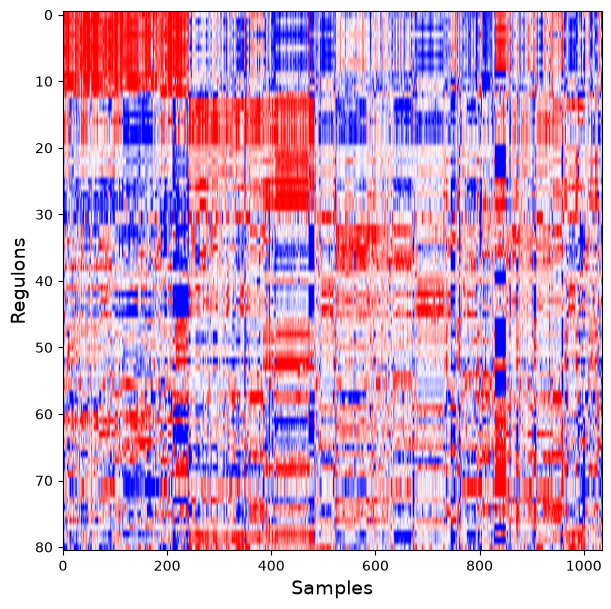

In [8]:
%%time
programs, _ = mnr.mosaic(dfr=eigengenes, clusterList=centroidClusters,
                          minClusterSize_x=minClusterSize, minClusterSize_y=5,
                          allow_singletons=False, max_groups=50,
                          saveFile=None, random_state=12)
transcriptional_programs, program_regulons = mnr.transcriptionalPrograms(programs, regulonModules)
program_list = [program_regulons["TP" + str(i)] for i in range(len(program_regulons))]
print(f"{len(program_list)} transcriptional programs")

In [9]:
%%time
import glob
mut_matrix = mut_matrix_samples_x_genes.T  # miner expects genes x samples
causalinf.causalNetworkAnalysis(
    regulon_matrix=regulonDf.copy(), expression_matrix=expressionData.copy(),
    reference_matrix=eigengenes.copy(), mutation_matrix=mut_matrix,
    resultsDirectory=os.path.join(BASE, "causal_results_dir"),
    minRegulons=1, significance_threshold=0.05, causalFolder="ecoli_knockouts")

files = glob.glob(os.path.join(BASE, "causal_results_dir", "ecoli_knockouts", "*_causal_results.csv"))
causal_results = pd.concat([pd.read_csv(f, index_col=0) for f in files], ignore_index=True)
for c in causal_results.columns[3:]:
    causal_results[c] = pd.to_numeric(causal_results[c], errors="coerce")
filtered = causal_results[
    (causal_results["-log10(p)_Regulon_stratification"] >= -np.log10(0.05)) &
    (causal_results["Fraction_of_edges_correctly_aligned"] >= 0.5) &
    (causal_results["RegulatorRegulon_Spearman_p-value"] <= 0.05) &
    (causal_results["-log10(p)_MutationRegulatorEdge"] >= -np.log10(0.05))
]
filtered.to_csv(os.path.join(BASE, "filteredCausalResults.csv"))
print(f"{len(causal_results)} raw causal flows -> {len(filtered)} passed all filters")

completed causal analysis in 0.02 minutes
150 raw causal flows -> 150 passed all filters
CPU times: user 610 ms, sys: 83.1 ms, total: 693 ms
Wall time: 1.55 s


In [10]:
%%time
WT_STRAIN_RE = re.compile(r"^Escherichia coli K-12 (MG1655|BW25113|W3110)$")

def crp_group(desc):
    low = str(desc).lower()
    if re.search(r"\bdel_crp\b", low) or re.search(r"\bcrp_del\w+", low):
        return "perturbed"
    if WT_STRAIN_RE.match(str(desc).strip()):
        return "WT"
    return "other"

meta = pd.read_csv(META_PATH).set_index("Unnamed: 0")
meta["crp_group"] = meta["Strain Description"].map(crp_group)
crp_project = meta.loc[meta.crp_group == "perturbed", "project"].iloc[0]   # "crp"
matched_samples = [s for s in meta.index[(meta.project == crp_project) & (meta.crp_group.isin(["perturbed", "WT"]))]
                   if s in expressionData.columns]

n_pert = (meta.loc[matched_samples, "crp_group"] == "perturbed").sum()
n_wt = (meta.loc[matched_samples, "crp_group"] == "WT").sum()
print(f"Matched design: {n_pert} perturbed (KO+domain-deletion) vs {n_wt} WT, all from project '{crp_project}'")

crp_gene_id = pd.read_csv(GENE_INFO_PATH).set_index("gene_name").loc["crp", "locus_tag"]
mut_matrix_crp_matched = pd.DataFrame(0, index=[crp_gene_id], columns=matched_samples)
perturbed_samples = [s for s in matched_samples if meta.loc[s, "crp_group"] == "perturbed"]
mut_matrix_crp_matched.loc[crp_gene_id, perturbed_samples] = 1

causalinf.causalNetworkAnalysis(
    regulon_matrix=regulonDf.copy(),
    expression_matrix=expressionData[matched_samples].copy(),
    reference_matrix=eigengenes[matched_samples].copy(),
    mutation_matrix=mut_matrix_crp_matched,
    resultsDirectory=os.path.join(BASE, "causal_results_dir"),
    minRegulons=1, significance_threshold=0.05, causalFolder="ecoli_crp_matched")

crp_files = glob.glob(os.path.join(BASE, "causal_results_dir", "ecoli_crp_matched", "*_causal_results.csv"))
crp_matched_results = pd.concat([pd.read_csv(f, index_col=0) for f in crp_files], ignore_index=True)
for c in crp_matched_results.columns[3:]:
    crp_matched_results[c] = pd.to_numeric(crp_matched_results[c], errors="coerce")
crp_matched_filtered = crp_matched_results[
    (crp_matched_results["-log10(p)_Regulon_stratification"] >= -np.log10(0.05)) &
    (crp_matched_results["Fraction_of_edges_correctly_aligned"] >= 0.5) &
    (crp_matched_results["RegulatorRegulon_Spearman_p-value"] <= 0.05) &
    (crp_matched_results["-log10(p)_MutationRegulatorEdge"] >= -np.log10(0.05))
]
print(f"CRP matched-control run: {len(crp_matched_results)} raw flows -> {len(crp_matched_filtered)} passed filters")

orig_crp_flows = filtered[filtered.Mutation == crp_gene_id]
print(f"\nOriginal design (vs all 1035 samples):    {len(orig_crp_flows)} CRP flows, "
      f"regulons {sorted(orig_crp_flows.Regulon.unique())}")
print(f"Matched design (vs same-project WT only): {len(crp_matched_filtered)} CRP flows, "
      f"regulons {sorted(crp_matched_filtered.Regulon.unique()) if len(crp_matched_filtered) else []}")
print(f"Regulons flagged causal in BOTH:           "
      f"{sorted(set(orig_crp_flows.Regulon) & set(crp_matched_filtered.Regulon))}")

Matched design: 17 perturbed (KO+domain-deletion) vs 3 WT, all from project 'crp'
completed causal analysis in 0.00 minutes
CRP matched-control run: 3 raw flows -> 1 passed filters

Original design (vs all 1035 samples):    2 CRP flows, regulons [np.int64(9), np.int64(71)]
Matched design (vs same-project WT only): 1 CRP flows, regulons [np.int64(71)]
Regulons flagged causal in BOTH:           [71]
CPU times: user 86 ms, sys: 7.18 ms, total: 93.2 ms
Wall time: 105 ms


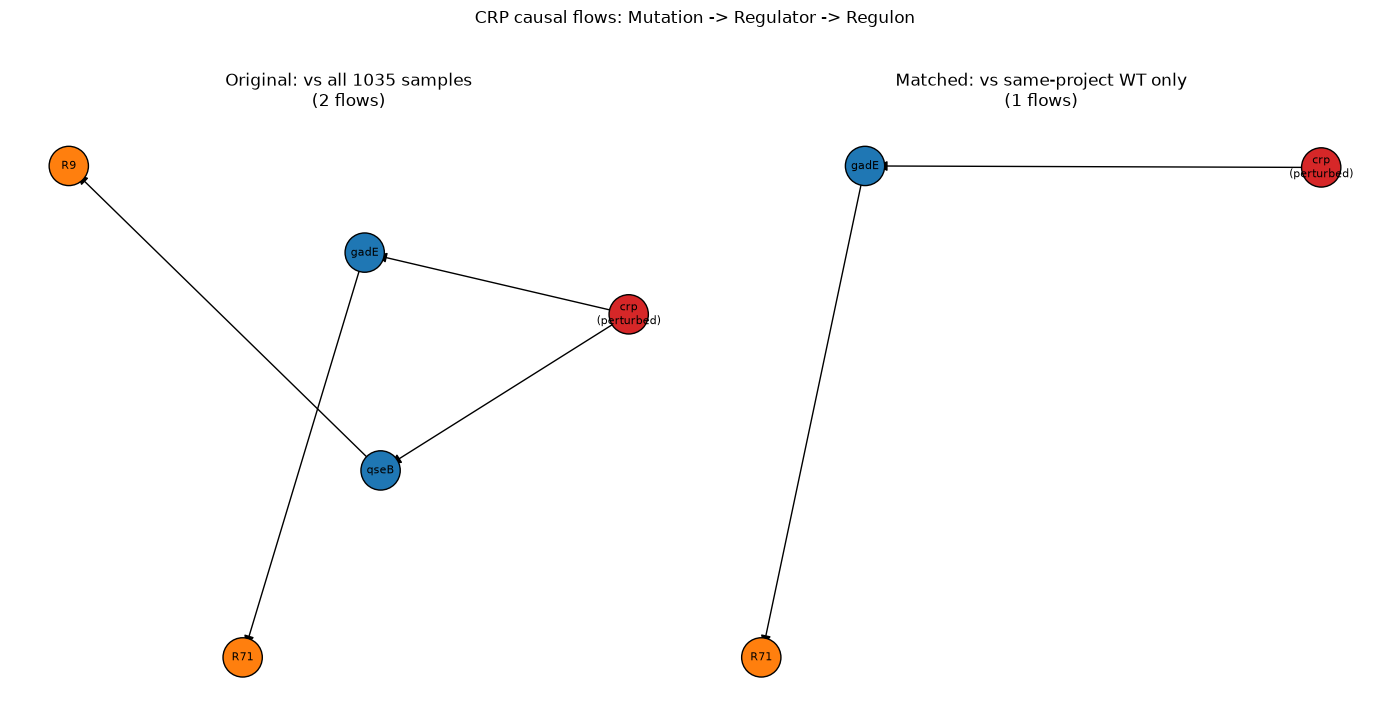

CPU times: user 269 ms, sys: 46.9 ms, total: 316 ms
Wall time: 364 ms


In [11]:
%%time
import networkx as nx
import matplotlib.pyplot as plt

gi_names = pd.read_csv(GENE_INFO_PATH).set_index("locus_tag")["gene_name"]
def name(x):
    return gi_names.get(x, x)

def build_graph(flows_df, mutation_id):
    G = nx.DiGraph()
    mut_label = f"{name(mutation_id)}\n(perturbed)"
    for _, row in flows_df.iterrows():
        reg_label = name(row["Regulator"])
        regulon_label = f"R{row['Regulon']}"
        G.add_edge(mut_label, reg_label)
        G.add_edge(reg_label, regulon_label)
    return G

G_orig = build_graph(orig_crp_flows, crp_gene_id)
G_matched = build_graph(crp_matched_filtered, crp_gene_id) if len(crp_matched_filtered) else nx.DiGraph()

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax, G, title in [(axs[0], G_orig, f"Original: vs all 1035 samples\n({len(orig_crp_flows)} flows)"),
                      (axs[1], G_matched, f"Matched: vs same-project WT only\n({len(crp_matched_filtered)} flows)")]:
    if len(G) == 0:
        ax.text(0.5, 0.5, "no flows survived\nthe matched-control filters", ha="center", va="center")
        ax.set_title(title); ax.axis("off"); continue
    pos = nx.spring_layout(G, seed=4, k=1.2)
    node_colors = ["tab:red" if "perturbed" in n else ("tab:orange" if n.startswith("R") else "tab:blue") for n in G]
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=800, edgecolors="k", ax=ax)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=15, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(title); ax.axis("off")
fig.suptitle("CRP causal flows: Mutation -> Regulator -> Regulon", y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(BASE, "fig_crp_network_comparison.png"), bbox_inches="tight", dpi=150)
plt.show()

In [14]:
%%time
gi = pd.read_csv(GENE_INFO_PATH).set_index("locus_tag")
# Cell 9d: which change moved the CRP flows?
ko_only = [s for s in expressionData.columns
           if re.search(r"\bdel_crp\b", str(meta.loc[s, "Strain Description"]).lower())]
mm = pd.DataFrame(0, index=[crp_gene_id], columns=expressionData.columns)
mm.loc[crp_gene_id, ko_only] = 1

causalinf.causalNetworkAnalysis(
    regulon_matrix=regulonDf.copy(), expression_matrix=expressionData.copy(),
    reference_matrix=eigengenes.copy(), mutation_matrix=mm,
    resultsDirectory=os.path.join(BASE, "causal_results_dir"),
    minRegulons=1, significance_threshold=0.05, causalFolder="ecoli_crp_ko_only")

r = pd.concat([pd.read_csv(f, index_col=0) for f in
               glob.glob(os.path.join(BASE, "causal_results_dir", "ecoli_crp_ko_only", "*_causal_results.csv"))])
for c in r.columns[3:]:
    r[c] = pd.to_numeric(r[c], errors="coerce")
r = r[(r["-log10(p)_Regulon_stratification"] >= -np.log10(0.05)) &
      (r["Fraction_of_edges_correctly_aligned"] >= 0.5) &
      (r["RegulatorRegulon_Spearman_p-value"] <= 0.05) &
      (r["-log10(p)_MutationRegulatorEdge"] >= -np.log10(0.05))]

print(f"KO-only anchor ({len(ko_only)} samples):")
print([(gi.loc[x, "gene_name"], f"R{y}") for x, y in zip(r.Regulator, r.Regulon)])
print("\nYour regulons R71 and R9 belong to:",
      regulonDf[regulonDf.Regulon_ID.isin([71, 9])].drop_duplicates("Regulon_ID")[["Regulon_ID", "Regulator"]]
      .assign(Regulator=lambda d: d.Regulator.map(lambda x: gi.loc[x, "gene_name"])).values.tolist())

completed causal analysis in 0.00 minutes
KO-only anchor (9 samples):
[('glnG', 'R45'), ('gadE', 'R71'), ('iscR', 'R69'), ('csgD', 'R16')]

Your regulons R71 and R9 belong to: []
CPU times: user 112 ms, sys: 20.6 ms, total: 133 ms
Wall time: 146 ms


In [15]:
%%time
genes_to_tf = {}
for tf, targets in tf_to_genes.items():
    for gene in targets:
        genes_to_tf.setdefault(gene, []).append(tf)

reglist = sorted(regulonDf["Regulator"].unique().tolist())
tf_network_rows = []
for tf in reglist:
    hits = mnr.setdiff(mnr.intersect(reglist, genes_to_tf.get(tf, [])), [tf])
    if not hits:
        continue
    tmp_y = np.array(expressionData.loc[tf, expressionData.columns])
    mean_rs, mean_coefs, hitlist = [], [], [hits]
    for threshold in np.arange(0.01, 0.21, 0.01):
        if len(hits) == 0:
            break
        tmp_x = np.array(expressionData.loc[hits, expressionData.columns])
        coefs, rs = [], []
        for _ in range(30):
            tt = mnr.train_test(tmp_x, tmp_y, expressionData.columns)
            clf = Lasso(random_state=0, alpha=0.1, fit_intercept=True)
            clf.fit(tt["x_train"].T, tt["y_train"])
            coefs.append(clf.coef_)
            pred = clf.predict(tt["x_test"].T)
            r, _ = stats.spearmanr(pred, tt["y_test"])
            rs.append(r)
        mean_coef = np.mean(np.vstack(coefs), axis=0)
        mean_coefs.append(mean_coef)
        mean_rs.append(np.nanmean(rs))
        hits = np.array(hits)[np.abs(mean_coef) > threshold]
        hitlist.append(hits)
        if len(hits) == 0:
            break
    if not mean_rs:
        continue
    thresh = 0.975 * mean_rs[0] if mean_rs[0] == mean_rs[0] else 0
    filt = [i for i, v in enumerate(mean_rs) if v == v and v < thresh]
    selection = (filt[0] - 1 if filt[0] > 0 else 0) if filt else len(mean_rs) - 1
    for h, coef in zip(hitlist[selection], mean_coefs[selection]):
        if abs(coef) > 0:
            tf_network_rows.append([h, coef, tf])

tf_network = pd.DataFrame(tf_network_rows, columns=["Source", "Edge", "Target"])
tf_network.to_csv(os.path.join(BASE, "tf_tf_network.csv"), index=False)

gi = pd.read_csv(GENE_INFO_PATH).set_index("locus_tag")
all_nodes = pd.unique(tf_network[["Source", "Target"]].values.ravel())
out_deg = [sum(tf_network["Source"] == n) for n in all_nodes]
in_deg = [sum(tf_network["Target"] == n) for n in all_nodes]
network_degrees = pd.DataFrame({
    "in_degree": in_deg, "out_degree": out_deg,
    "out/in": [o / i if i > 0 else np.nan for o, i in zip(out_deg, in_deg)],
    "gene_name": [gi.loc[n, "gene_name"] if n in gi.index else n for n in all_nodes]
}, index=all_nodes).sort_values(["out_degree", "in_degree"], ascending=[False, True])
network_degrees.to_csv(os.path.join(BASE, "tf_tf_network_degrees.csv"))
print(network_degrees.head(10))

       in_degree  out_degree  out/in gene_name
b3067          0          10     NaN      rpoD
b3357          1           5     5.0       crp
b0889          1           3     3.0       lrp
b3261          1           3     3.0       fis
b3516          2           3     1.5      gadX
b4113          0           2     NaN      basR
b0683          1           2     2.0       fur
b1334          2           2     1.0       fnr
b3021          0           1     NaN      mqsA
b0145          0           1     NaN      dksA
CPU times: user 15.2 s, sys: 1.09 s, total: 16.3 s
Wall time: 16.4 s


In [16]:
%%time
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.neighbors import kneighbors_graph
from sklearn.metrics import adjusted_rand_score as ari
import networkx as nx
import umap

FIGDIR = os.path.join(BASE, "figures")
os.makedirs(FIGDIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 150, "font.size": 10})

g = lambda x: gi.loc[x, "gene_name"] if x in gi.index else x
dfr = overExpressedMembersMatrix - underExpressedMembersMatrix

sample_order = [s for st in states for s in st]
state_label = pd.Series({s: i for i, st in enumerate(states) for s in st})
prog_order = [r for p in program_list for r in p]
prog_order += [r for r in dfr.index if r not in prog_order]
state_bounds = np.cumsum([len(s) for s in states])[:-1]
prog_bounds = np.cumsum([len(p) for p in program_list])[:-1]

reg_of = regulonDf.drop_duplicates("Regulon_ID").set_index("Regulon_ID")["Regulator"]
reg_of.index = reg_of.index.astype(str)

def rlabel(r):
    return f"R{r} ({g(reg_of[r])})" if r in reg_of.index else f"R{r}"

figs = []
def save(fig, name):
    fig.savefig(os.path.join(FIGDIR, f"{name}.png"), bbox_inches="tight")
    figs.append(fig)
    print("saved", name)

CPU times: user 4.93 s, sys: 364 ms, total: 5.29 s
Wall time: 5.72 s


saved fig01_regulon_activity_clustered
CPU times: user 453 ms, sys: 92.3 ms, total: 545 ms
Wall time: 577 ms


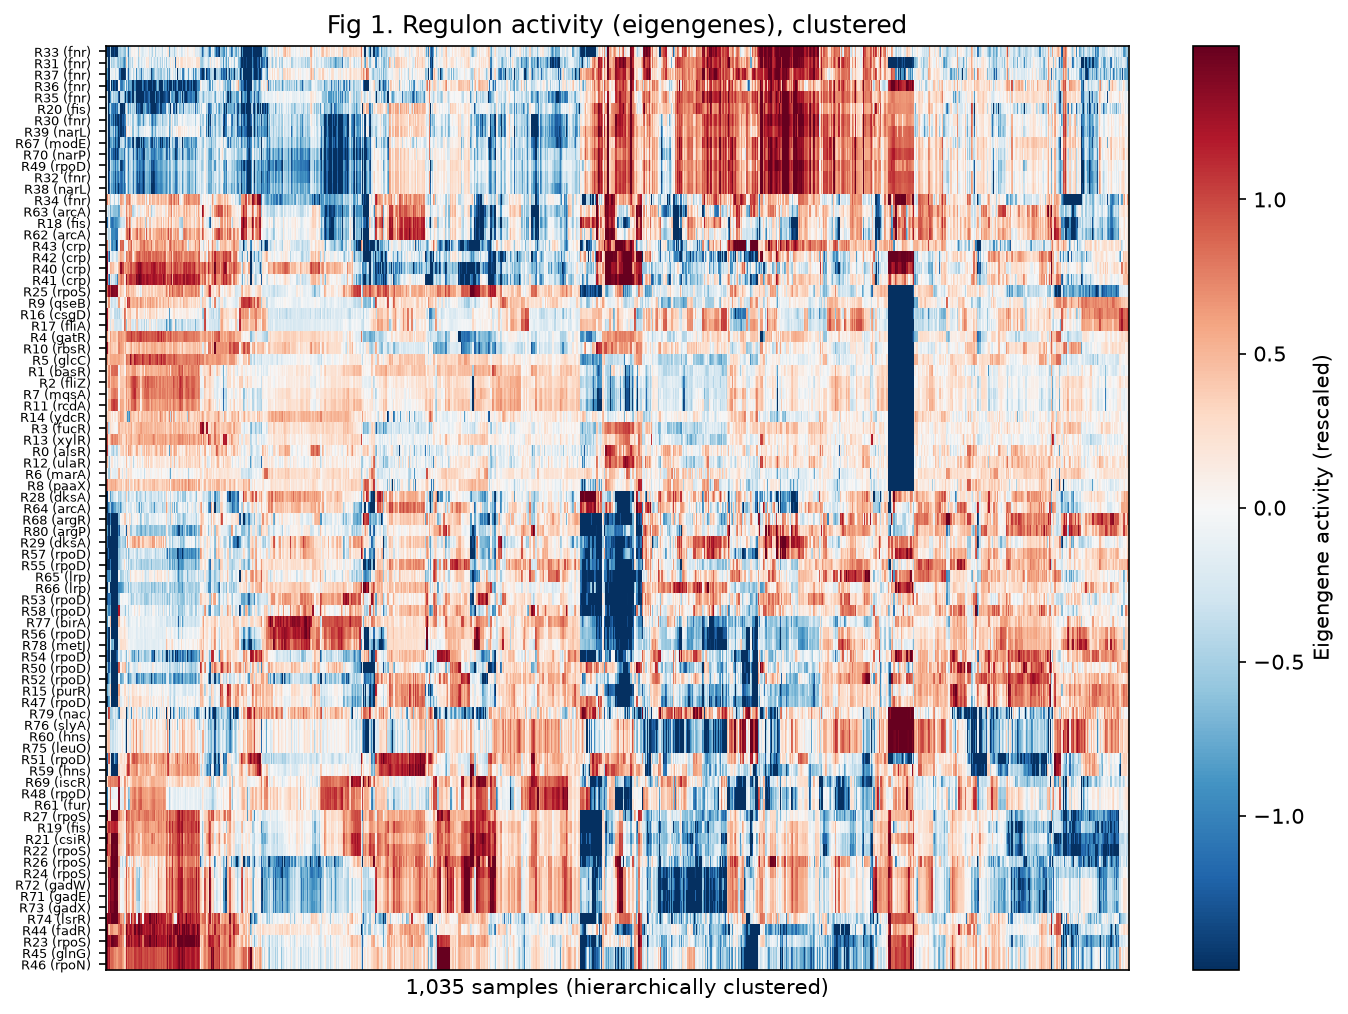

In [17]:
%%time
Z_r = leaves_list(linkage(eigengenes.values, "average", metric="correlation"))
Z_s = leaves_list(linkage(eigengenes.values.T, "average", metric="correlation"))
m = eigengenes.iloc[Z_r, Z_s]
v = np.percentile(np.abs(m.values), 95)

fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(m, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v, interpolation="nearest")
ax.set_yticks(range(len(m))); ax.set_yticklabels([rlabel(r) for r in m.index], fontsize=6)
ax.set_xticks([]); ax.set_xlabel("1,035 samples (hierarchically clustered)")
ax.set_title("Fig 1. Regulon activity (eigengenes), clustered"); ax.grid(False)
fig.colorbar(im, ax=ax, label="Eigengene activity (rescaled)")
save(fig, "fig01_regulon_activity_clustered")

saved fig02_programs_by_states_mosaic
CPU times: user 385 ms, sys: 85.4 ms, total: 470 ms
Wall time: 484 ms


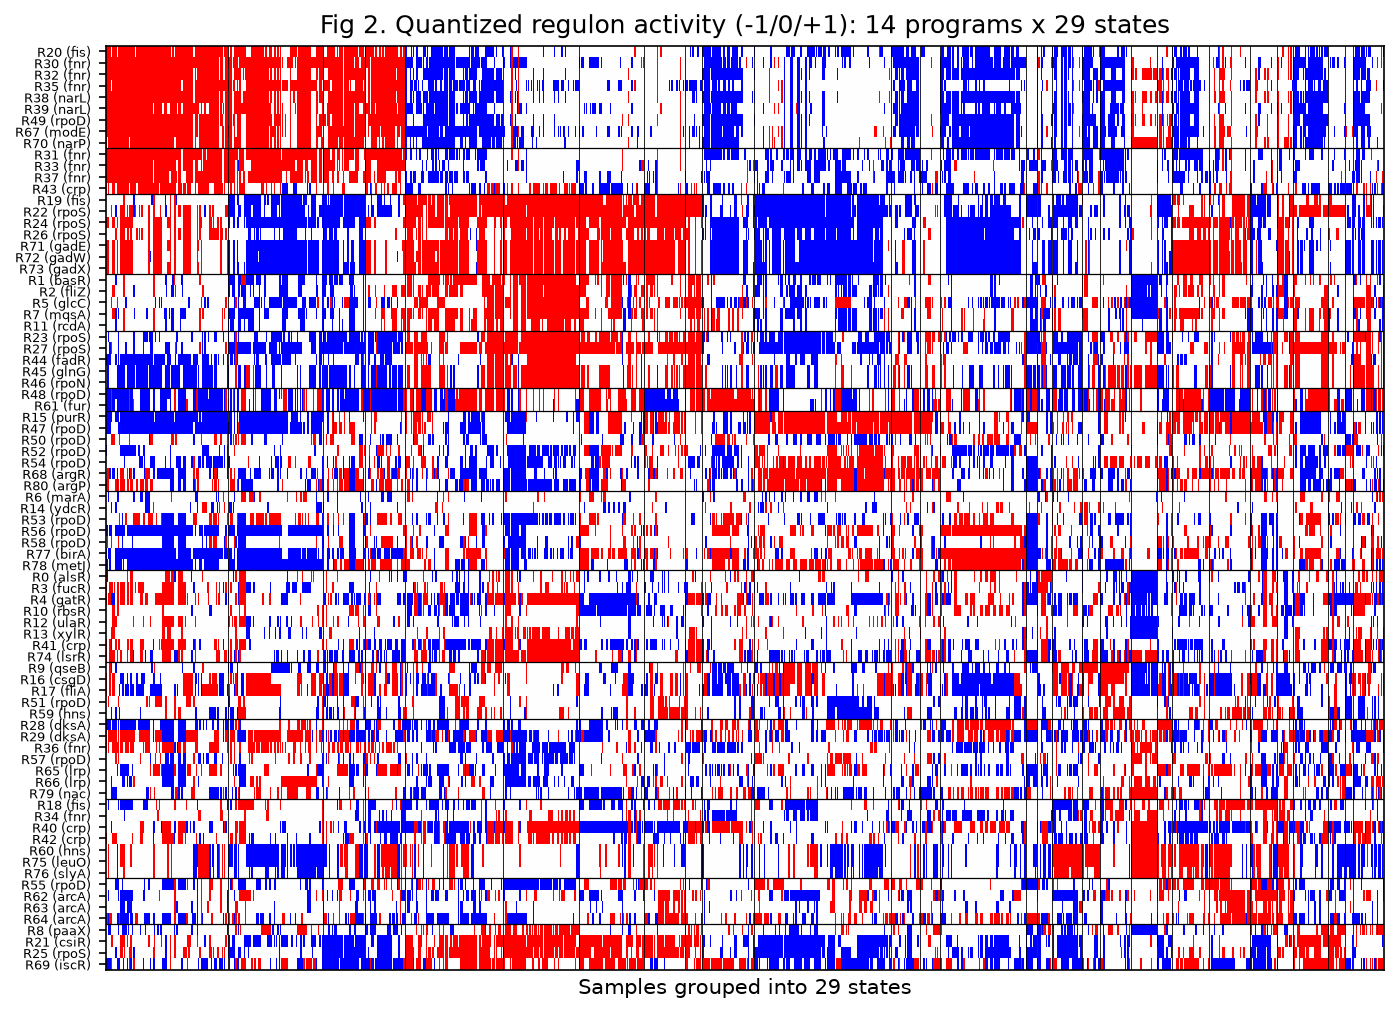

In [18]:
%%time
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(dfr.loc[prog_order, sample_order], aspect="auto", cmap="bwr", vmin=-1, vmax=1, interpolation="nearest")
for b in state_bounds: ax.axvline(b - .5, color="k", lw=.4)
for b in prog_bounds: ax.axhline(b - .5, color="k", lw=.6)
ax.set_yticks(range(len(prog_order))); ax.set_yticklabels([rlabel(r) for r in prog_order], fontsize=6)
ax.set_xticks([]); ax.set_xlabel(f"Samples grouped into {len(states)} states")
ax.set_title(f"Fig 2. Quantized regulon activity (-1/0/+1): {len(program_list)} programs x {len(states)} states")
ax.grid(False)
save(fig, "fig02_programs_by_states_mosaic")

saved fig03_overexpressed_bicluster
CPU times: user 101 ms, sys: 46.2 ms, total: 147 ms
Wall time: 152 ms


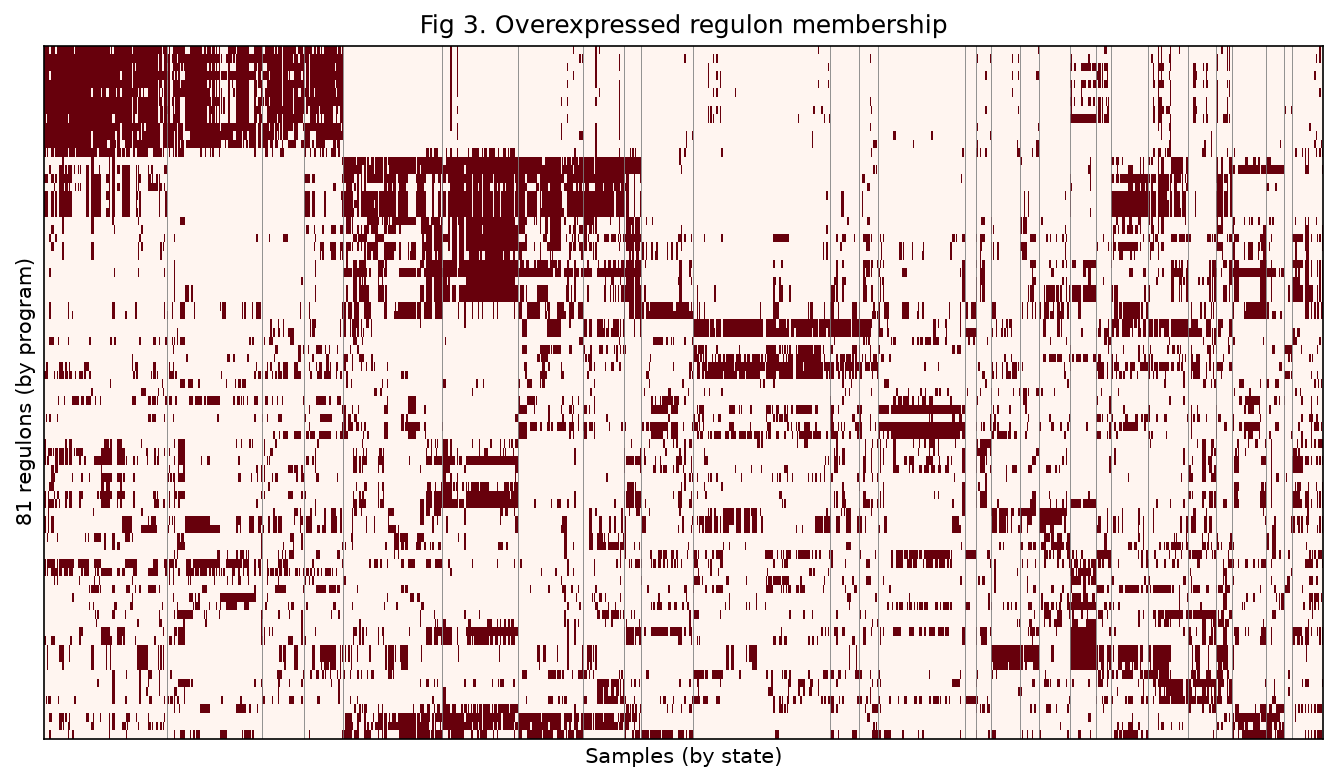

In [19]:
%%time
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(overExpressedMembersMatrix.loc[prog_order, sample_order], aspect="auto", cmap="Reds", vmin=0, vmax=1, interpolation="nearest")
for b in state_bounds: ax.axvline(b - .5, color="grey", lw=.4)
ax.set_yticks([]); ax.set_xticks([])
ax.set_ylabel(f"{len(prog_order)} regulons (by program)"); ax.set_xlabel("Samples (by state)")
ax.set_title("Fig 3. Overexpressed regulon membership"); ax.grid(False)
save(fig, "fig03_overexpressed_bicluster")

saved fig04_program_activity_per_state
CPU times: user 257 ms, sys: 86.4 ms, total: 344 ms
Wall time: 397 ms


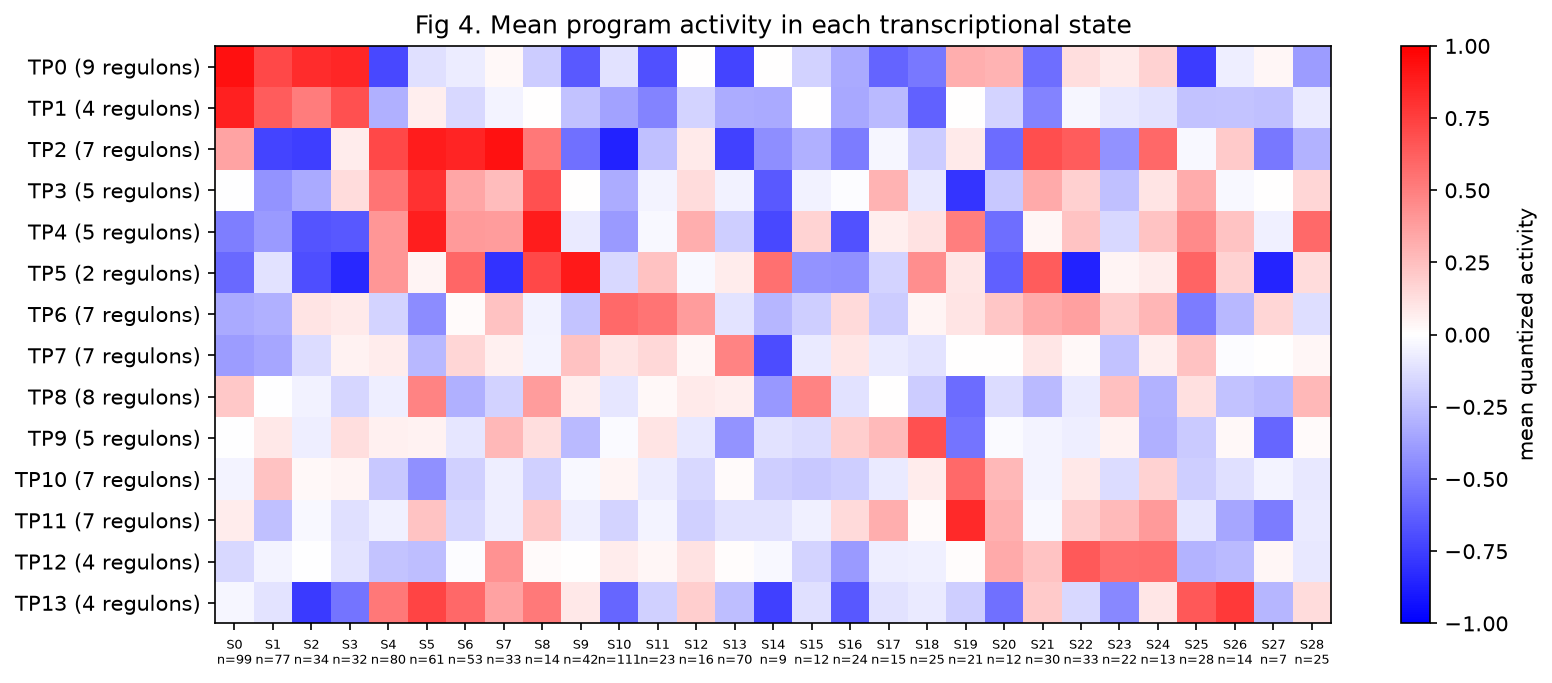

In [20]:
%%time
pa = pd.DataFrame({f"TP{i}": dfr.loc[p].mean() for i, p in enumerate(program_list)}).T
ps = pd.DataFrame({f"S{j}": pa[st].mean(axis=1) for j, st in enumerate(states)})

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(ps, aspect="auto", cmap="bwr", vmin=-1, vmax=1)
ax.set_yticks(range(len(ps))); ax.set_yticklabels([f"{i} ({len(p)} regulons)" for i, p in zip(ps.index, program_list)])
ax.set_xticks(range(ps.shape[1])); ax.set_xticklabels([f"{c}\nn={len(s)}" for c, s in zip(ps.columns, states)], fontsize=6)
ax.set_title("Fig 4. Mean program activity in each transcriptional state"); ax.grid(False)
fig.colorbar(im, ax=ax, label="mean quantized activity")
save(fig, "fig04_program_activity_per_state")

saved fig05_umap_states
CPU times: user 8.97 s, sys: 649 ms, total: 9.62 s
Wall time: 10.1 s


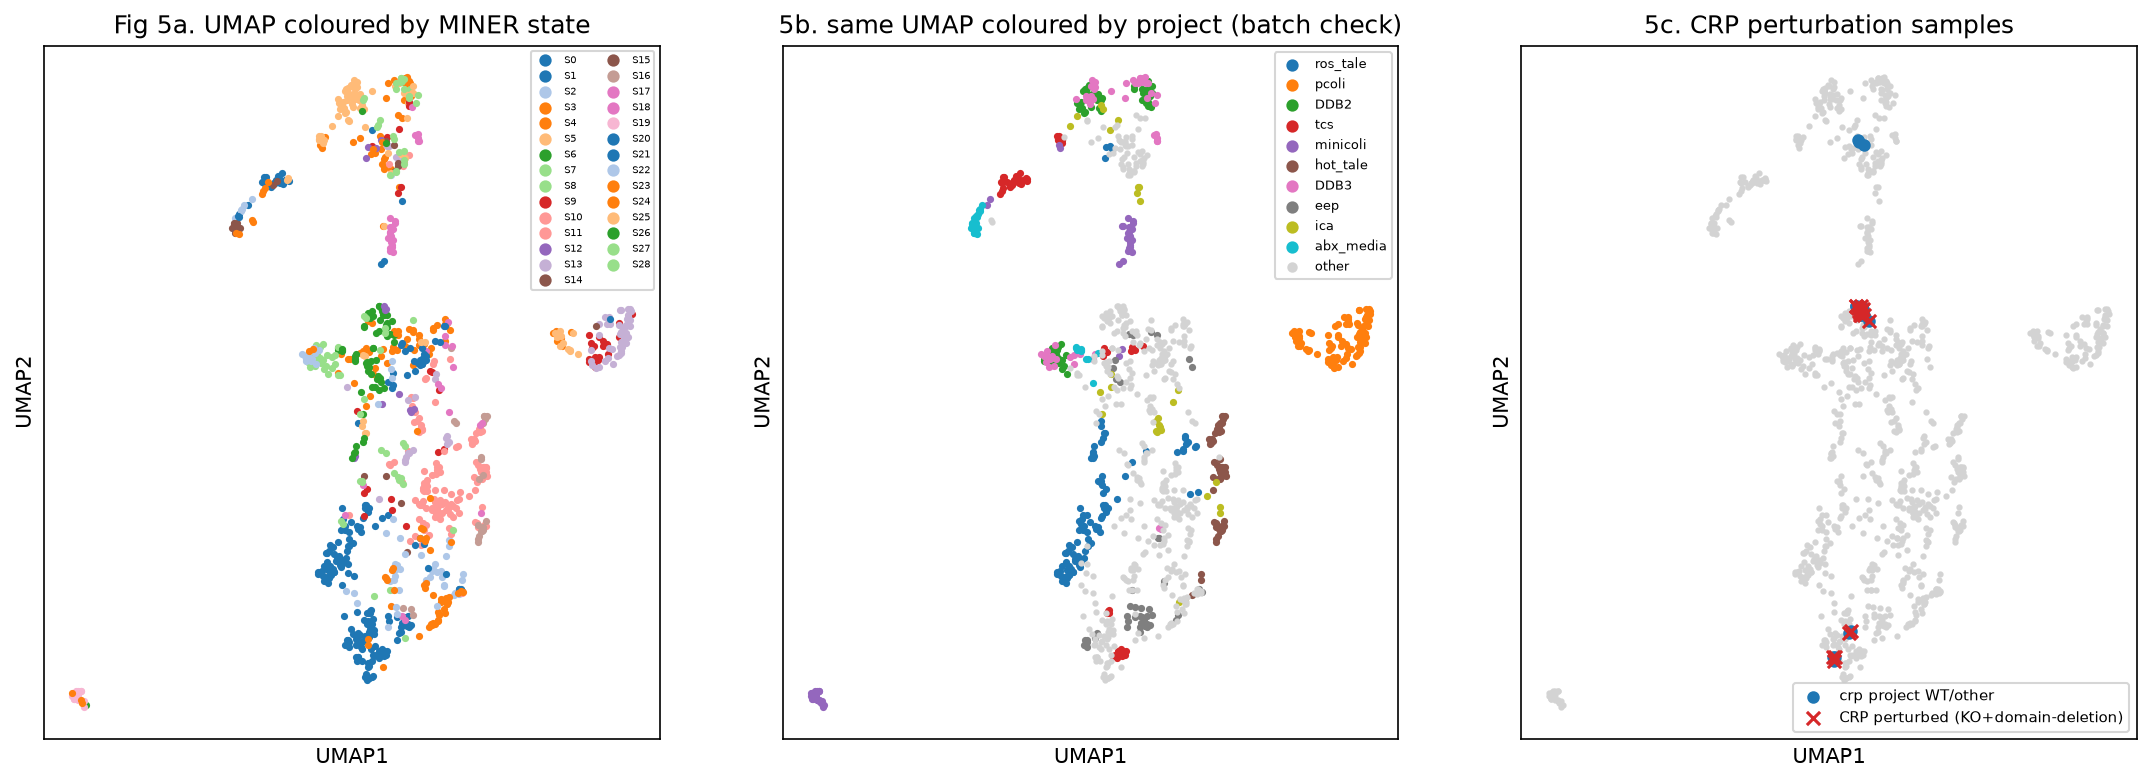

In [21]:
%%time
emb = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=12).fit_transform(dfr.T.values)
emb = pd.DataFrame(emb, index=dfr.columns, columns=["u1", "u2"])

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
cm = plt.get_cmap("tab20", len(states))
for j, st in enumerate(states):
    axs[0].scatter(emb.loc[st, "u1"], emb.loc[st, "u2"], s=6, color=cm(j % 20), label=f"S{j}")
axs[0].set_title("Fig 5a. UMAP coloured by MINER state"); axs[0].legend(fontsize=5, ncol=2, markerscale=2)

top = meta["project"].value_counts().index[:10]
for p in top:
    idx = meta.index[meta.project == p]
    axs[1].scatter(emb.loc[idx, "u1"], emb.loc[idx, "u2"], s=6, label=p)
rest = meta.index[~meta.project.isin(top)]
axs[1].scatter(emb.loc[rest, "u1"], emb.loc[rest, "u2"], s=4, c="lightgrey", label="other")
axs[1].set_title("5b. same UMAP coloured by project (batch check)"); axs[1].legend(fontsize=6, markerscale=2)

ko = mut_matrix_samples_x_genes.index[mut_matrix_samples_x_genes[crp_gene_id] == 1]
crpproj = meta.index[meta.project == crp_project]
axs[2].scatter(emb.u1, emb.u2, s=4, c="lightgrey")
axs[2].scatter(emb.loc[crpproj, "u1"], emb.loc[crpproj, "u2"], s=25, c="tab:blue", label="crp project WT/other")
axs[2].scatter(emb.loc[ko, "u1"], emb.loc[ko, "u2"], s=40, c="tab:red", marker="x", label="CRP perturbed (KO+domain-deletion)")
axs[2].set_title("5c. CRP perturbation samples"); axs[2].legend(fontsize=7)

for a in axs:
    a.set_xticks([]); a.set_yticks([]); a.set_xlabel("UMAP1"); a.set_ylabel("UMAP2")
save(fig, "fig05_umap_states")

saved fig06_cluster_method_comparison
CPU times: user 1.43 s, sys: 1.07 s, total: 2.51 s
Wall time: 900 ms


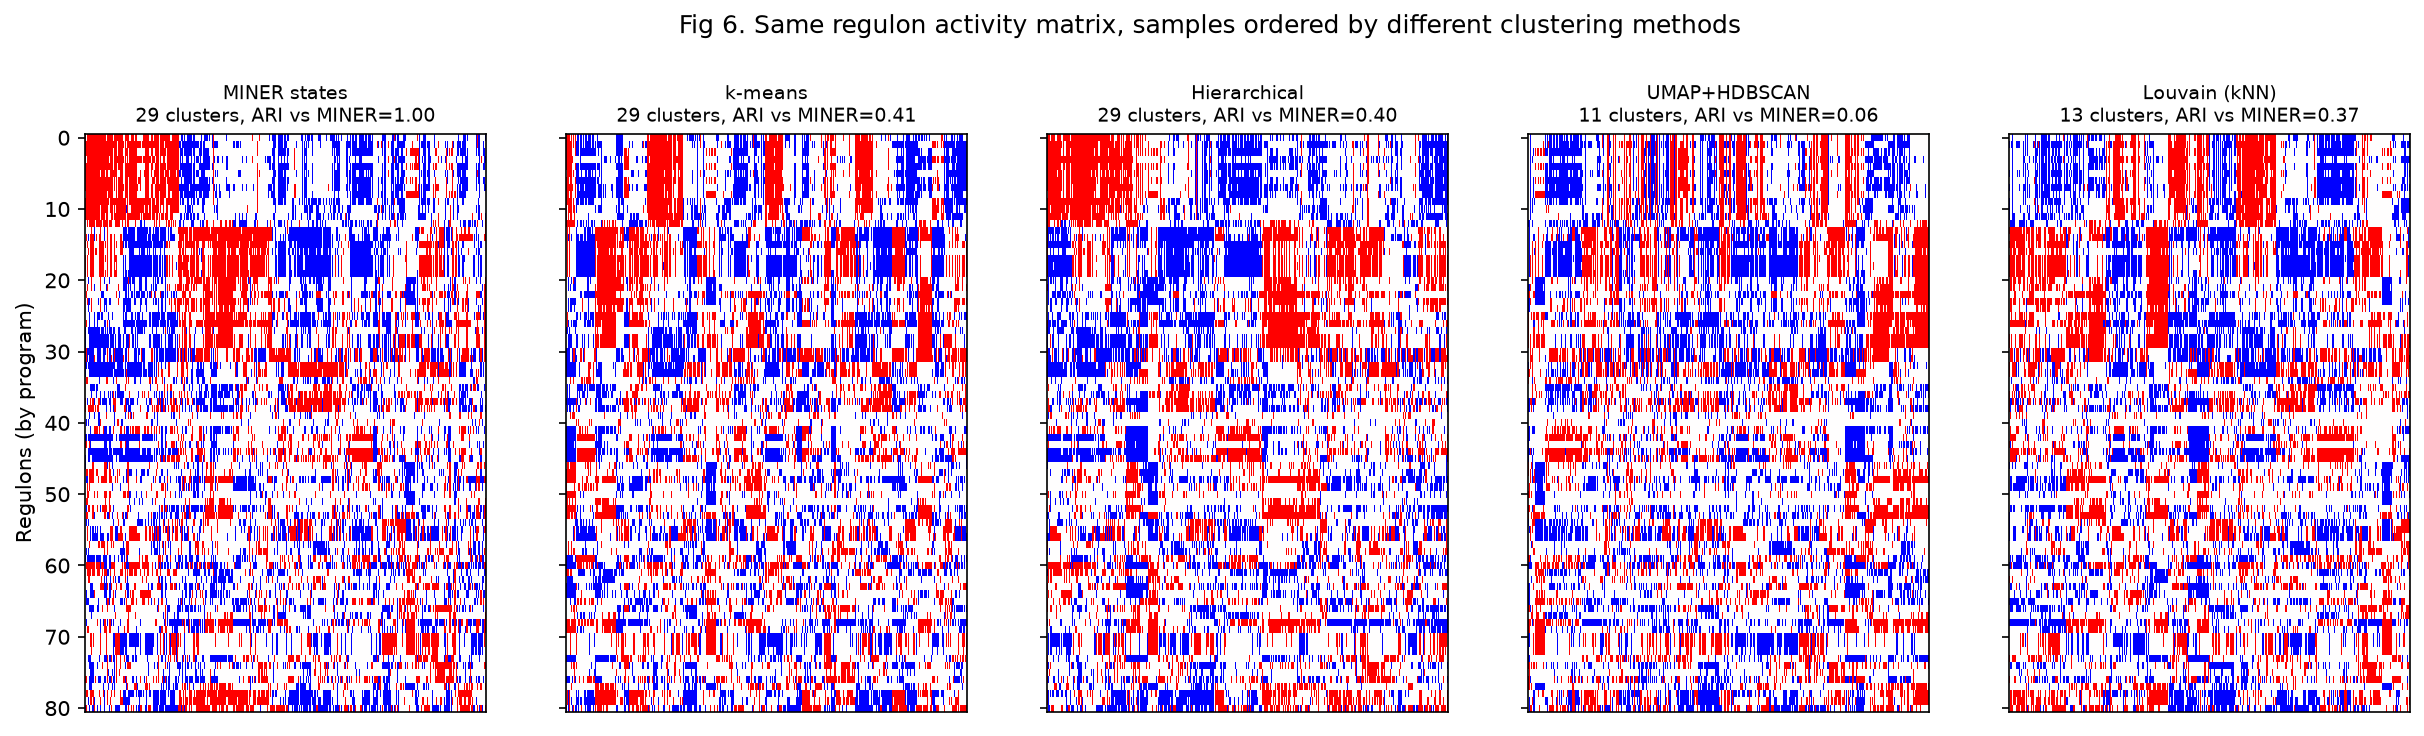

In [22]:
%%time
X = dfr.T.values
k = len(states)
labels = {
    "MINER states": state_label.reindex(dfr.columns).values,
    "k-means": KMeans(n_clusters=k, n_init=10, random_state=12).fit_predict(X),
    "Hierarchical": fcluster(linkage(X, "average", metric="hamming"), k, "maxclust"),
    "UMAP+HDBSCAN": HDBSCAN(min_cluster_size=11).fit_predict(emb.values),
}
G_knn = nx.from_scipy_sparse_array(kneighbors_graph(X, 15, include_self=False))
comm = nx.community.louvain_communities(G_knn, seed=12)
lv = np.zeros(len(X), int)
for i, c in enumerate(comm): lv[list(c)] = i
labels["Louvain (kNN)"] = lv

fig, axs = plt.subplots(1, len(labels), figsize=(20, 5), sharey=True)
for a, (name_, lab) in zip(axs, labels.items()):
    order = np.argsort(lab, kind="stable")
    a.imshow(dfr.loc[prog_order].values[:, order], aspect="auto", cmap="bwr", vmin=-1, vmax=1, interpolation="nearest")
    n = len(set(lab)); r = ari(labels["MINER states"], lab)
    a.set_title(f"{name_}\n{n} clusters, ARI vs MINER={r:.2f}", fontsize=9); a.set_xticks([]); a.grid(False)
axs[0].set_ylabel("Regulons (by program)")
fig.suptitle("Fig 6. Same regulon activity matrix, samples ordered by different clustering methods", y=1.04)
save(fig, "fig06_cluster_method_comparison")

saved fig07_tf_tf_network
CPU times: user 222 ms, sys: 19.4 ms, total: 241 ms
Wall time: 245 ms


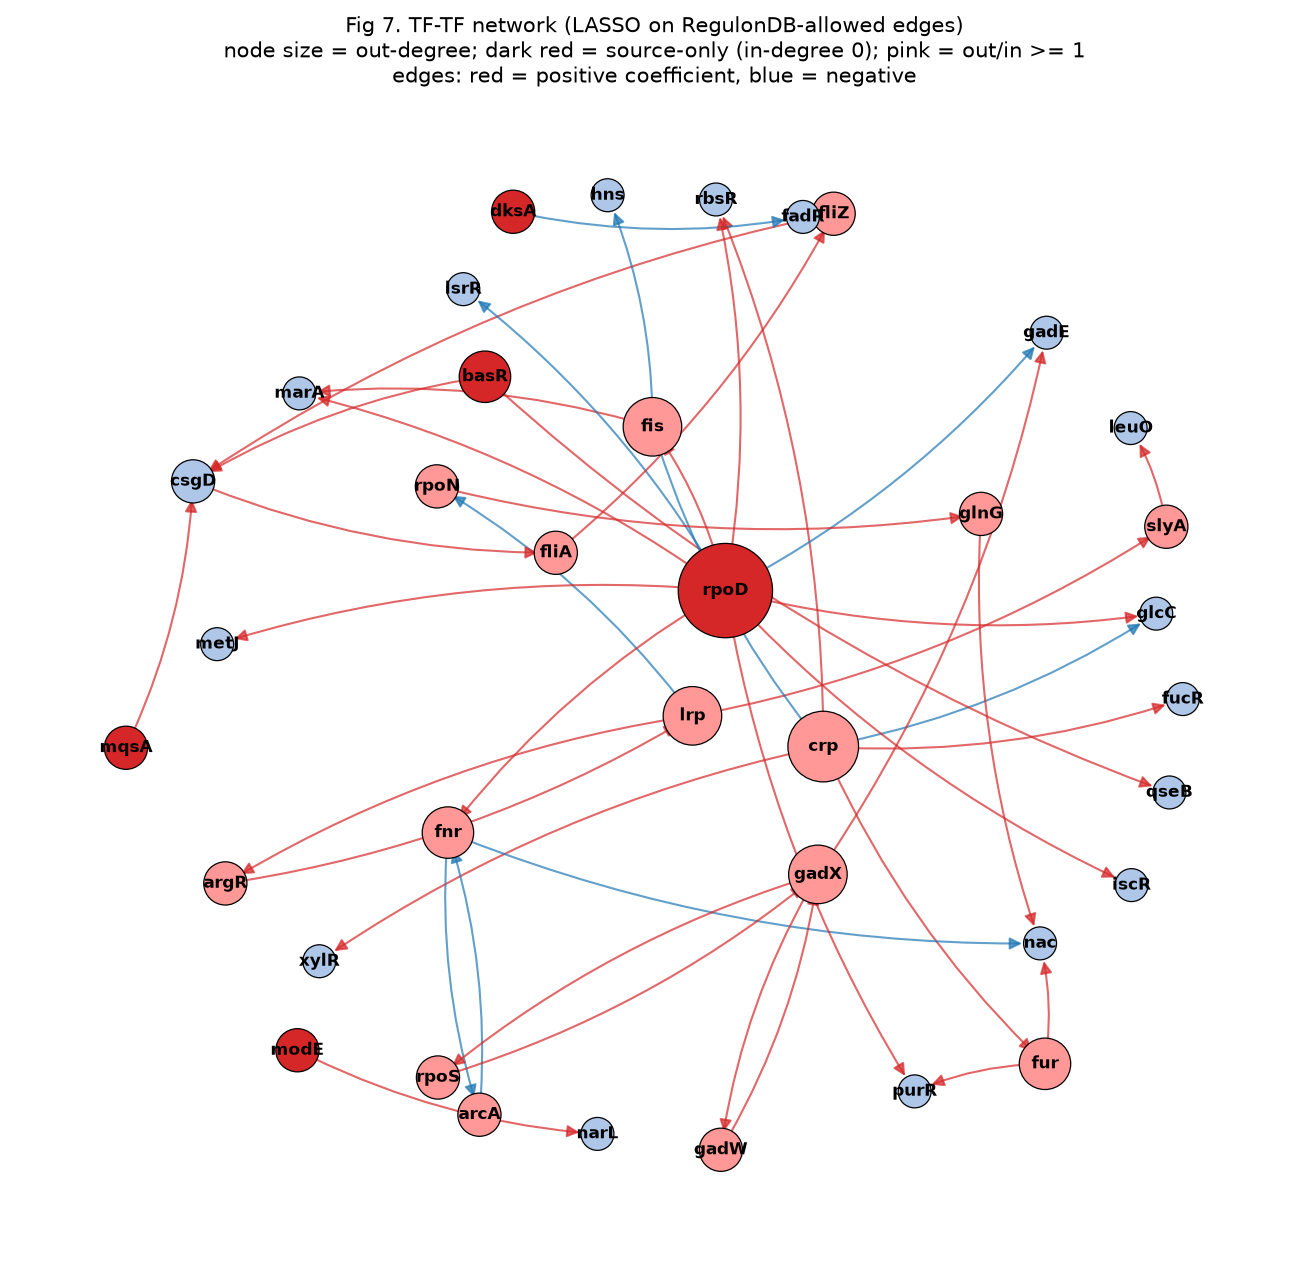

In [23]:
%%time
G = nx.DiGraph()
for s, e, t in tf_network[["Source", "Edge", "Target"]].values:
    G.add_edge(g(s), g(t), w=e)
outd, ind = dict(G.out_degree()), dict(G.in_degree())
pos = nx.spring_layout(G, seed=4, k=1.1)

fig, ax = plt.subplots(figsize=(11, 10))
col = ["#d62728" if ind[n] == 0 and outd[n] > 0 else ("#ff9896" if outd[n] >= max(ind[n], 1) else "#aec7e8") for n in G]
nx.draw_networkx_nodes(G, pos, node_color=col, node_size=[250 + 180 * outd[n] for n in G], edgecolors="k", linewidths=.6, ax=ax)
nx.draw_networkx_edges(G, pos, edge_color=["tab:red" if G[u][v]["w"] > 0 else "tab:blue" for u, v in G.edges],
                       arrows=True, arrowsize=12, alpha=.7, connectionstyle="arc3,rad=0.1", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold", ax=ax)
ax.set_title("Fig 7. TF-TF network (LASSO on RegulonDB-allowed edges)\n"
             "node size = out-degree; dark red = source-only (in-degree 0); pink = out/in >= 1\n"
             "edges: red = positive coefficient, blue = negative", fontsize=10)
ax.axis("off")
save(fig, "fig07_tf_tf_network")

saved fig08_tf_degrees
CPU times: user 169 ms, sys: 31.7 ms, total: 201 ms
Wall time: 207 ms


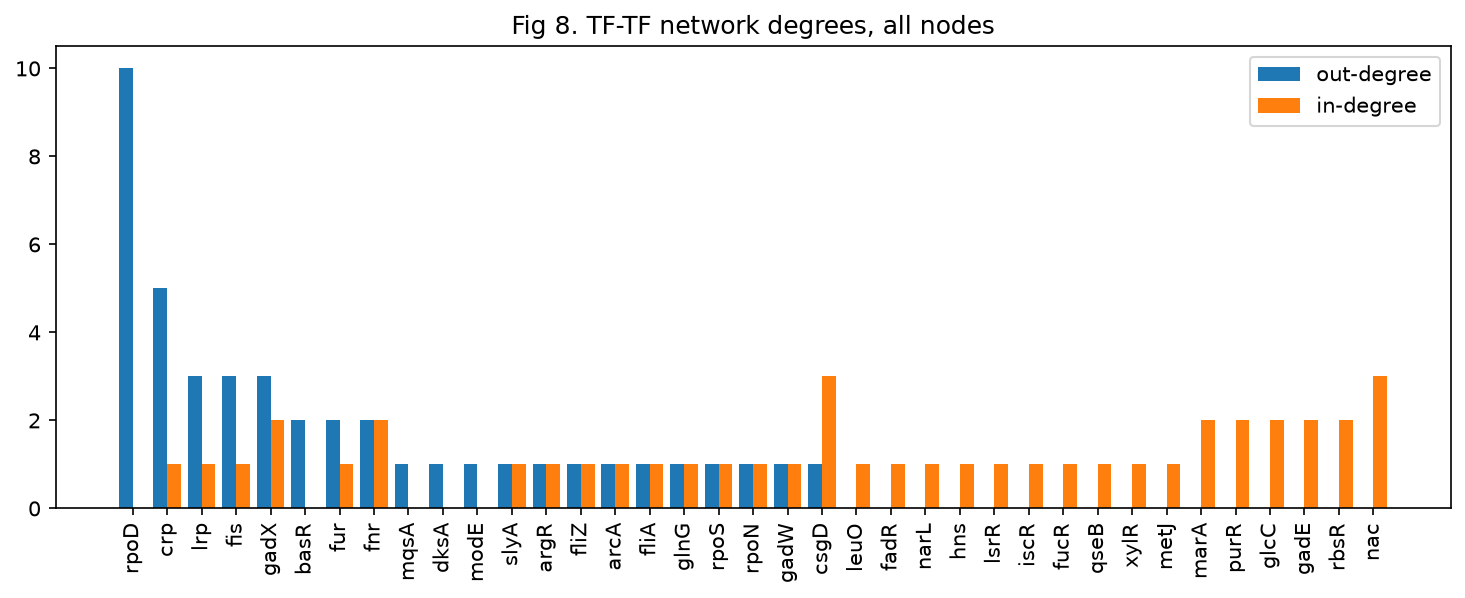

In [24]:
%%time
deg = pd.DataFrame({"out": outd, "in": ind}).sort_values(["out", "in"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(deg))
ax.bar(x - .2, deg["out"], .4, label="out-degree")
ax.bar(x + .2, deg["in"], .4, label="in-degree")
ax.set_xticks(x); ax.set_xticklabels(deg.index, rotation=90); ax.legend()
ax.set_title("Fig 8. TF-TF network degrees, all nodes")
save(fig, "fig08_tf_degrees")

saved fig09_regulator_jaccard
CPU times: user 418 ms, sys: 58.4 ms, total: 476 ms
Wall time: 485 ms


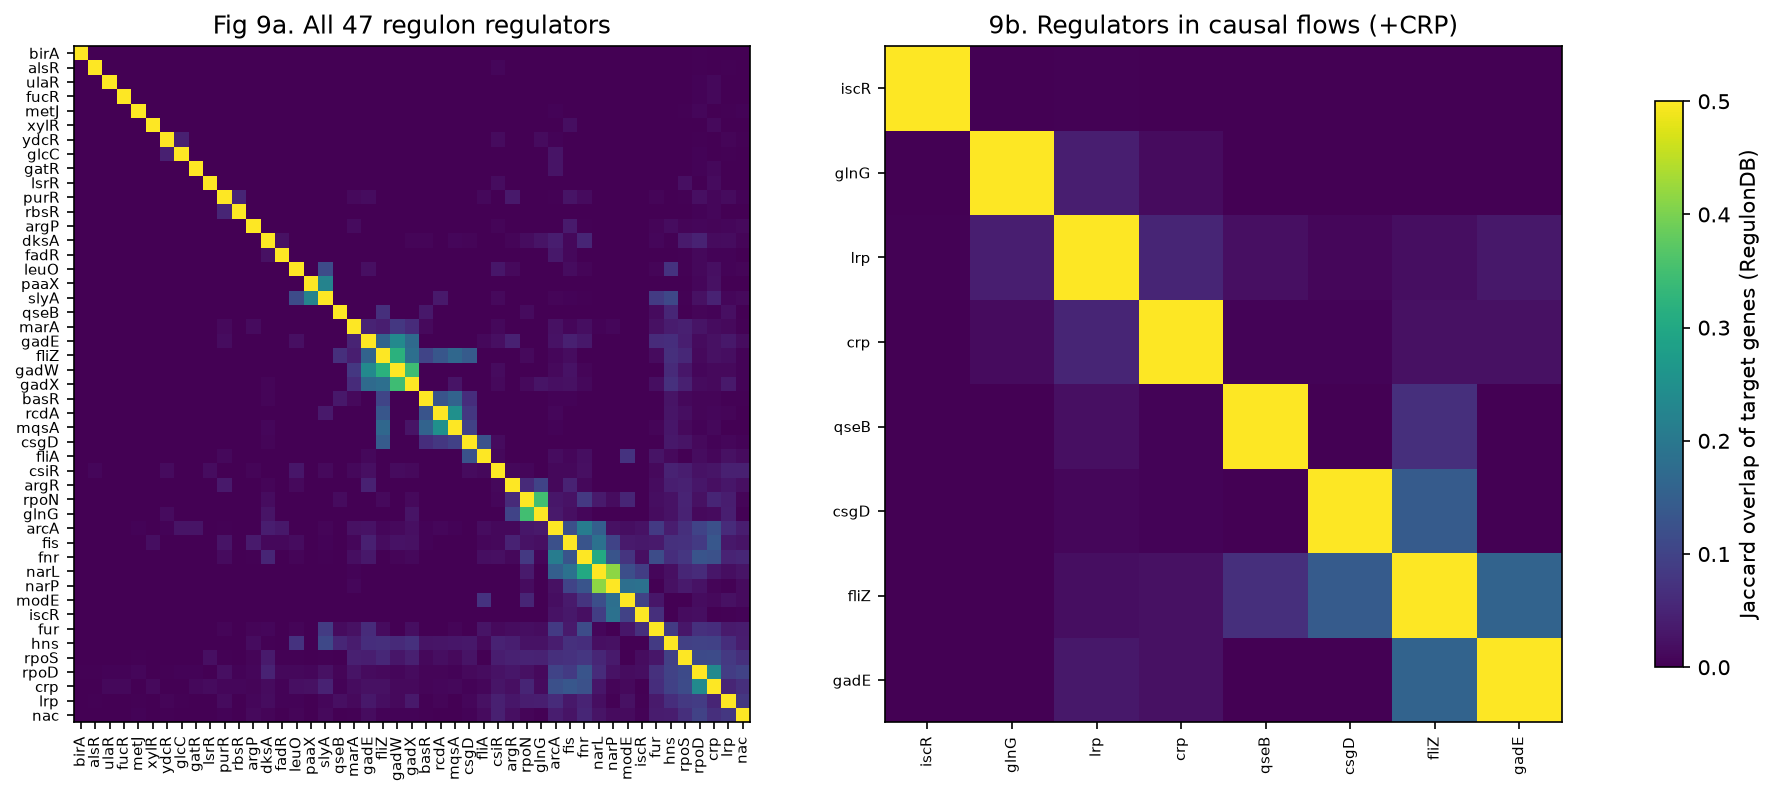

In [25]:
%%time
def jacc_for(regs, title, ax):
    regs = [r for r in regs if r in tf_to_genes]
    J = pd.DataFrame([[len(set(tf_to_genes[a]) & set(tf_to_genes[b])) / len(set(tf_to_genes[a]) | set(tf_to_genes[b]))
                        for b in regs] for a in regs],
                      index=[g(r) for r in regs], columns=[g(r) for r in regs])
    o = leaves_list(linkage(1 - J.values[np.triu_indices(len(J), 1)], "average")) if len(J) > 2 else range(len(J))
    J = J.iloc[o, o]
    im = ax.imshow(J, cmap="viridis", vmin=0, vmax=.5)
    ax.set_xticks(range(len(J))); ax.set_xticklabels(J.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(J))); ax.set_yticklabels(J.index, fontsize=7); ax.set_title(title); ax.grid(False)
    return im

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
all_regs = sorted(regulonDf.Regulator.unique())
act = filtered[filtered.MutationRegulatorEdge == 1].Regulator.unique().tolist()
rep = filtered[filtered.MutationRegulatorEdge == -1].Regulator.unique().tolist()
im = jacc_for(all_regs, f"Fig 9a. All {len(all_regs)} regulon regulators", axs[0])
jacc_for(sorted(set(act) | set(rep) | {crp_gene_id}), "9b. Regulators in causal flows (+CRP)", axs[1])
fig.colorbar(im, ax=axs, label="Jaccard overlap of target genes (RegulonDB)", shrink=.7)
save(fig, "fig09_regulator_jaccard")

saved fig10_validation_crp_matched
CPU times: user 248 ms, sys: 21.9 ms, total: 270 ms
Wall time: 277 ms


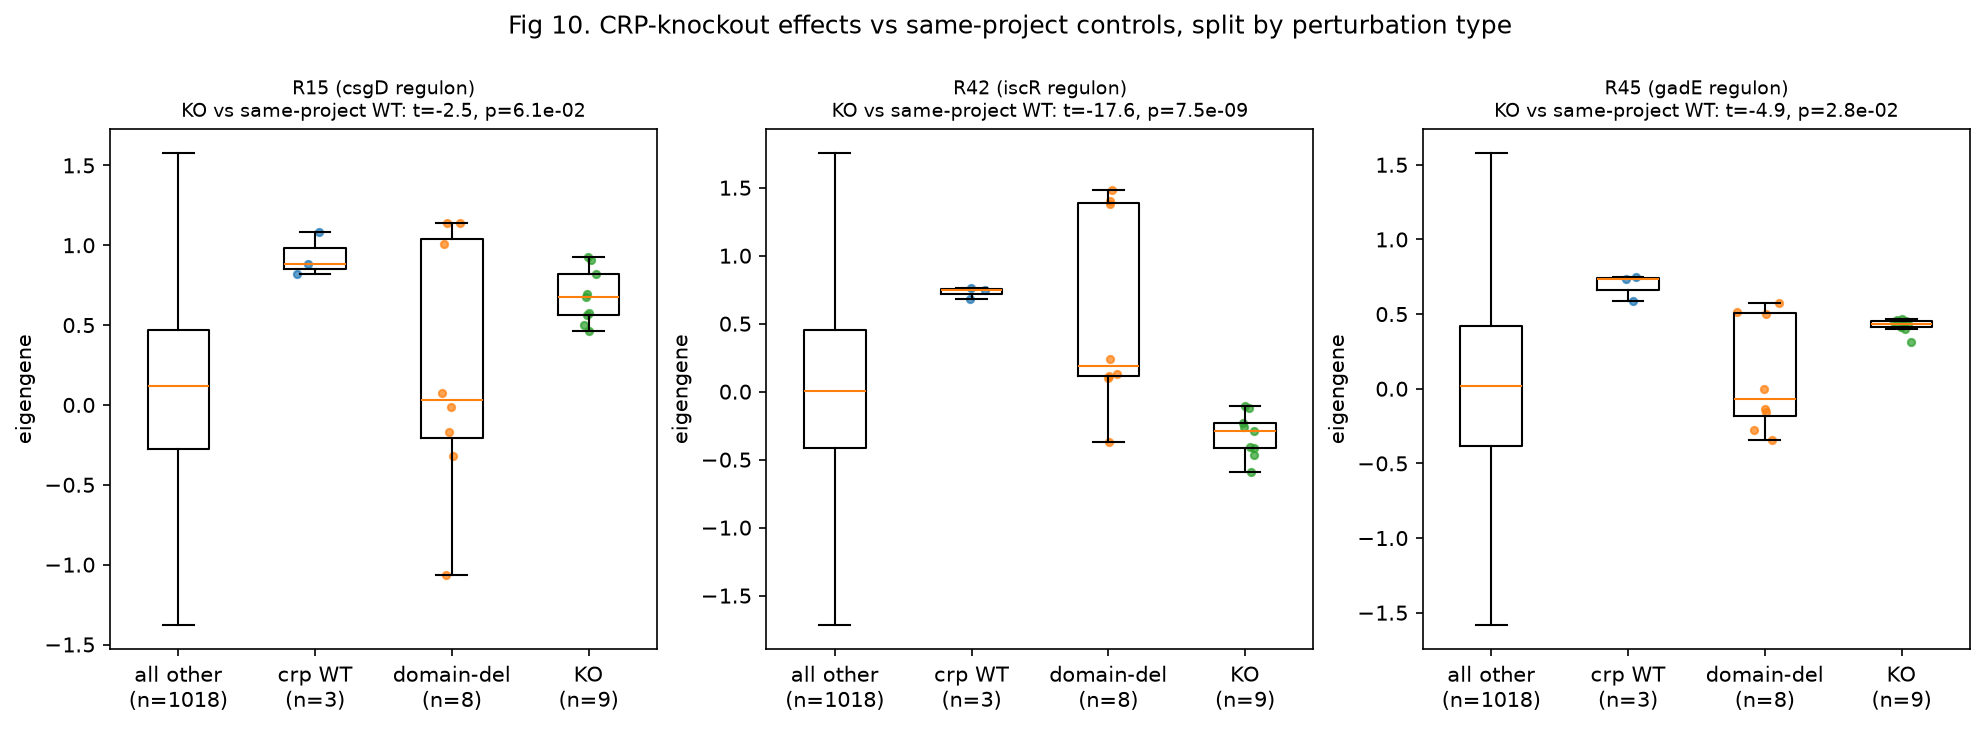

In [26]:
%%time
def crp_subgroup(desc):
    low = str(desc).lower()
    if re.search(r"\bdel_crp\b", low): return "KO"
    if re.search(r"\bcrp_del\w+", low): return "domain_deletion"
    if WT_STRAIN_RE.match(str(desc).strip()): return "WT"
    return "other"

meta["crp_subgroup"] = meta["Strain Description"].map(crp_subgroup)
ko_only = meta.index[meta.crp_subgroup == "KO"]
dd_only = meta.index[meta.crp_subgroup == "domain_deletion"]
crp_wt = meta.index[(meta.project == crp_project) & (meta.crp_subgroup == "WT")]
others = [s for s in eigengenes.columns if s not in ko_only and s not in dd_only]

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (reg, r) in zip(axs, [("b1040", "15"), ("b2531", "42"), ("b3512", "45")]):
    if r not in eigengenes.index:
        continue
    data = [eigengenes.loc[r, others], eigengenes.loc[r, crp_wt], eigengenes.loc[r, dd_only], eigengenes.loc[r, ko_only]]
    a.boxplot(data, tick_labels=[f"all other\n(n={len(others)})", f"crp WT\n(n={len(crp_wt)})",
                                   f"domain-del\n(n={len(dd_only)})", f"KO\n(n={len(ko_only)})"], showfliers=False)
    for i, d in enumerate(data[1:], start=2):
        a.scatter(np.random.normal(i, .05, len(d)), d, s=12, alpha=.7)
    t, p = stats.ttest_ind(eigengenes.loc[r, ko_only], eigengenes.loc[r, crp_wt], equal_var=False)
    a.set_title(f"R{r} ({g(reg)} regulon)\nKO vs same-project WT: t={t:.1f}, p={p:.1e}", fontsize=9)
    a.set_ylabel("eigengene")
fig.suptitle("Fig 10. CRP-knockout effects vs same-project controls, split by perturbation type", y=1.05)
save(fig, "fig10_validation_crp_matched")

saved fig11_validation_mediation
CPU times: user 97.5 ms, sys: 29.4 ms, total: 127 ms
Wall time: 134 ms


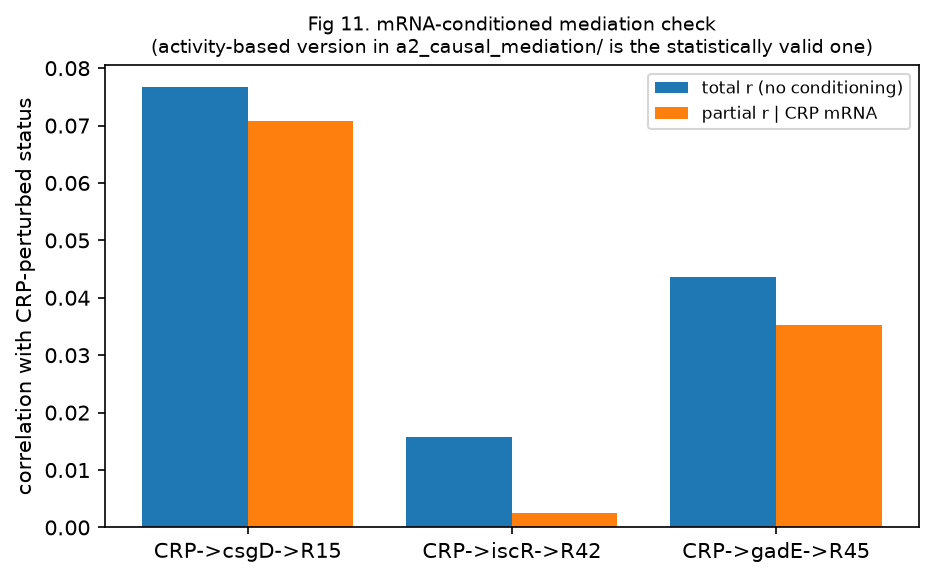

In [27]:
%%time
status = mut_matrix_samples_x_genes[crp_gene_id].reindex(eigengenes.columns).values.astype(float)
rows = []
for reg, r in [("b1040", "15"), ("b2531", "42"), ("b3512", "45")]:
    if r not in eigengenes.index:
        continue
    y = eigengenes.loc[r].values
    mm = expressionData.loc[reg, eigengenes.columns].values
    res = lambda v: v - np.polyval(np.polyfit(mm, v, 1), mm)
    rows.append((f"CRP->{g(reg)}->R{r}", stats.pearsonr(status, y)[0], stats.pearsonr(res(status), res(y))[0]))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(rows))
ax.bar(x - .2, [r[1] for r in rows], .4, label="total r (no conditioning)")
ax.bar(x + .2, [r[2] for r in rows], .4, label="partial r | CRP mRNA")
ax.axhline(0, color="k", lw=.6); ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows])
ax.set_ylabel("correlation with CRP-perturbed status"); ax.legend(fontsize=8)
ax.set_title("Fig 11. mRNA-conditioned mediation check\n(activity-based version in a2_causal_mediation/ is the statistically valid one)", fontsize=9)
save(fig, "fig11_validation_mediation")

saved fig12_validation_causal_specificity
CPU times: user 315 ms, sys: 90.1 ms, total: 405 ms
Wall time: 432 ms


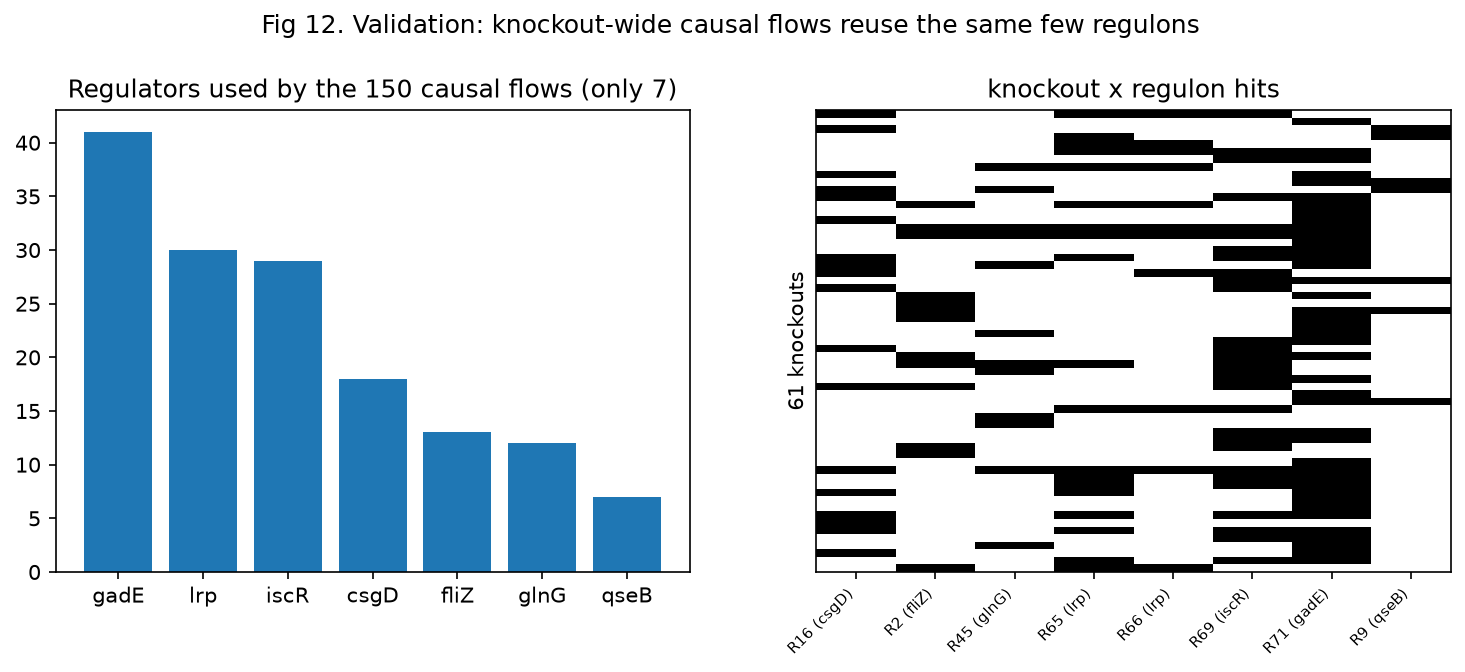

In [28]:
%%time
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
vc = filtered.Regulator.map(g).value_counts()
axs[0].bar(vc.index, vc.values)
axs[0].set_title(f"Regulators used by the {len(filtered)} causal flows (only {len(vc)})")

mat = pd.crosstab(filtered.Mutation.map(g), filtered.Regulon.astype(str).map(rlabel))
axs[1].imshow(mat.values > 0, aspect="auto", cmap="Greys", interpolation="nearest")
axs[1].set_xticks(range(mat.shape[1])); axs[1].set_xticklabels(mat.columns, rotation=45, ha="right", fontsize=7)
axs[1].set_yticks([]); axs[1].set_ylabel(f"{mat.shape[0]} knockouts"); axs[1].set_title("knockout x regulon hits")
axs[1].grid(False)
fig.suptitle("Fig 12. Validation: knockout-wide causal flows reuse the same few regulons", y=1.04)
save(fig, "fig12_validation_causal_specificity")

In [29]:
print("kernel alive")

kernel alive
